<a href="https://colab.research.google.com/github/njw257/bigdata/blob/main/week10_5685599_%EB%82%A8%EC%A2%85%EC%9A%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 10주차 과제
빅데이터프로그래밍 · 통계학과

**이름:남종욱**
**학번:5685599**

## 과제 내용
전이학습 모델과 직접 구현한 CNN의 학습 시간과 결과를 비교합니다.

## 제출 방법
모든 셀을 실행해 출력과 그래프가 보이는 상태로 저장한 뒤 `week10_학번_이름.ipynb` 로 제출합니다.

**런타임 > 런타임 유형 변경 > T4 GPU** 를 먼저 선택하세요.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import pandas as pd
import time

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# 고정 조건 — 바꾸지 마세요
EPOCHS, BATCH, SEED, IMG_SIZE = 10, 16, 42, 224

NORM = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.ToTensor(), NORM,
])
eval_tf = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(IMG_SIZE), transforms.ToTensor(), NORM,
])

raw_train = datasets.Flowers102("./data", split="train", download=True, transform=train_tf)
raw_val   = datasets.Flowers102("./data", split="val",   download=True, transform=eval_tf)

KEEP = [0, 1, 2, 3, 4]
NAMES = ["pink primrose", "hard-leaved orchid", "canterbury bells", "sweet pea", "english marigold"]

class Subset5(torch.utils.data.Dataset):
    def __init__(self, base):
        self.base = base
        self.idx = [i for i, lb in enumerate(base._labels) if lb in KEEP]
        self.remap = {c: i for i, c in enumerate(KEEP)}
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        x, y = self.base[self.idx[i]]
        return x, self.remap[y]

train_loader = DataLoader(Subset5(raw_train), batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(Subset5(raw_val),   batch_size=32, shuffle=False)
N_CLASSES = len(KEEP)
print(f"학습 {len(train_loader.dataset)}장 · 검증 {len(val_loader.dataset)}장 · 클래스 {N_CLASSES}개")


device: cuda


100%|██████████| 345M/345M [00:13<00:00, 25.1MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.63MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 15.2MB/s]


학습 50장 · 검증 50장 · 클래스 5개


## 공통 함수
아래를 그대로 쓰고 모델만 바꿔 실험하세요.


In [2]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


def run(model, lr, epochs=EPOCHS, seed=SEED):
    torch.manual_seed(seed)
    model = model.to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    start = time.time()
    hist = []
    for epoch in range(1, epochs + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(model, val_loader))
        if epoch % 5 == 0:
            print(f"  epoch {epoch}  검증 {hist[-1][1]:.4f}")
    return {"model": model, "hist": hist, "time": time.time() - start,
            "train_params": sum(p.numel() for p in model.parameters() if p.requires_grad)}


## 문제 1. 직접 구현한 CNN (25점)
8·9주차에서 배운 것을 써서 CNN을 직접 작성하고 학습하세요.

- Conv 층 3개 이상
- BatchNorm 또는 Dropout 중 하나 이상 적용
- 입력은 (3, 224, 224) 컬러 이미지
- 왜 그렇게 구성했는지 주석으로 적으세요


In [3]:
# 답안

# 직접 구현한 CNN 모델 정의
class ScratchCNN(nn.Module):
    def __init__(self, n_classes=N_CLASSES):
        super().__init__()

        # 다양한 이미지 특징 추출을 위해 Conv 층 4개 구성
        # 학습 안정화를 위해 BatchNorm 적용
        # 특징 맵 크기를 줄이기 위해 MaxPooling 적용
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
        )

        # 과적합 방지를 위해 Dropout 적용 및 5개 클래스 분류
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# 직접 구현한 CNN 학습
torch.manual_seed(SEED)
results = {}
results["직접 만든 CNN"] = run(ScratchCNN(), lr=1e-3)

# 학습 결과 출력
r = results["직접 만든 CNN"]
print(f"학습 파라미터: {r['train_params']:,}개")
print(f"최종 검증 정확도: {r['hist'][-1][1]:.4f}")
print(f"학습 시간: {r['time']:.1f}초")


  epoch 5  검증 0.4000
  epoch 10  검증 0.6800
학습 파라미터: 242,181개
최종 검증 정확도: 0.6800
학습 시간: 11.0초


## 문제 2. 전이학습 모델 (25점)
`resnet18` 을 불러와 마지막 계층을 교체하고 학습하세요.

- `in_features` 를 하드코딩하지 말고 읽어서 쓰세요
- 특징 추출 부분은 고정합니다
- 학습 파라미터 수를 출력하세요


In [4]:
# 답안

# 전이학습 모델 생성 함수
def transfer(mode):
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # 마지막 계층만 학습
    if mode == "fc_only":
        for p in m.parameters():
            p.requires_grad = False

    # layer4와 마지막 계층만 학습
    elif mode == "layer4":
        for p in m.parameters():
            p.requires_grad = False
        for p in m.layer4.parameters():
            p.requires_grad = True

    # 마지막 계층을 5개 클래스에 맞게 교체
    m.fc = nn.Linear(m.fc.in_features, N_CLASSES)

    return m


# 마지막 계층만 학습
torch.manual_seed(SEED)
results["전이 · fc만"] = run(transfer("fc_only"), lr=1e-3)

# 학습 결과 출력
r = results["전이 · fc만"]
print(f"학습 파라미터: {r['train_params']:,}개")
print(f"최종 검증 정확도: {r['hist'][-1][1]:.4f}")
print(f"학습 시간: {r['time']:.1f}초")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


  epoch 5  검증 0.5600
  epoch 10  검증 0.8600
학습 파라미터: 2,565개
최종 검증 정확도: 0.8600
학습 시간: 6.8초


## 문제 3. 층 고정 방식 비교 (20점)
아래 세 가지를 비교하세요.

1. 마지막 계층만 학습 (lr=1e-3)
2. `layer4` + 마지막 계층 학습 (lr=1e-4)
3. 전체 미세조정 (lr=1e-4)

각 방식의 학습 파라미터 수도 함께 적으세요.


In [5]:
# 답안

# layer4와 마지막 계층 학습
torch.manual_seed(SEED)
print("전이학습 layer4+fc")
results["전이 · layer4+fc"] = run(transfer("layer4"), lr=1e-4)

# 전체 미세조정
torch.manual_seed(SEED)
print("\n전이학습 전체 미세조정")
results["전이 · 전체"] = run(transfer("full"), lr=1e-4)

# 세 가지 전이학습 방식의 결과 출력
for name in ["전이 · fc만", "전이 · layer4+fc", "전이 · 전체"]:
    r = results[name]
    print(f"\n{name}")
    print(f"학습 파라미터: {r['train_params']:,}개")
    print(f"최종 검증 정확도: {r['hist'][-1][1]:.4f}")
    print(f"학습 시간: {r['time']:.1f}초")


전이학습 layer4+fc
  epoch 5  검증 0.9400
  epoch 10  검증 0.9000

전이학습 전체 미세조정
  epoch 5  검증 0.9200
  epoch 10  검증 0.8800

전이 · fc만
학습 파라미터: 2,565개
최종 검증 정확도: 0.8600
학습 시간: 6.8초

전이 · layer4+fc
학습 파라미터: 8,396,293개
최종 검증 정확도: 0.9000
학습 시간: 7.3초

전이 · 전체
학습 파라미터: 11,179,077개
최종 검증 정확도: 0.8800
학습 시간: 6.9초


## 문제 4. 비교표와 학습 곡선 (20점)
모든 모델을 하나의 표로 정리하세요.

| 모델 | 학습 파라미터 | 최종 검증 정확도 | 최고 검증 정확도 | 학습 시간 |

학습 곡선을 겹쳐 그린 그림도 함께 넣으세요.


            모델    학습 파라미터  최종 검증 정확도  최고 검증 정확도  학습 시간(초)
     직접 만든 CNN    242,181       0.68       0.68      11.0
      전이 · fc만      2,565       0.86       0.90       6.8
전이 · layer4+fc  8,396,293       0.90       0.96       7.3
       전이 · 전체 11,179,077       0.88       1.00       6.9

가장 좋은 모델: 전이 · 전체


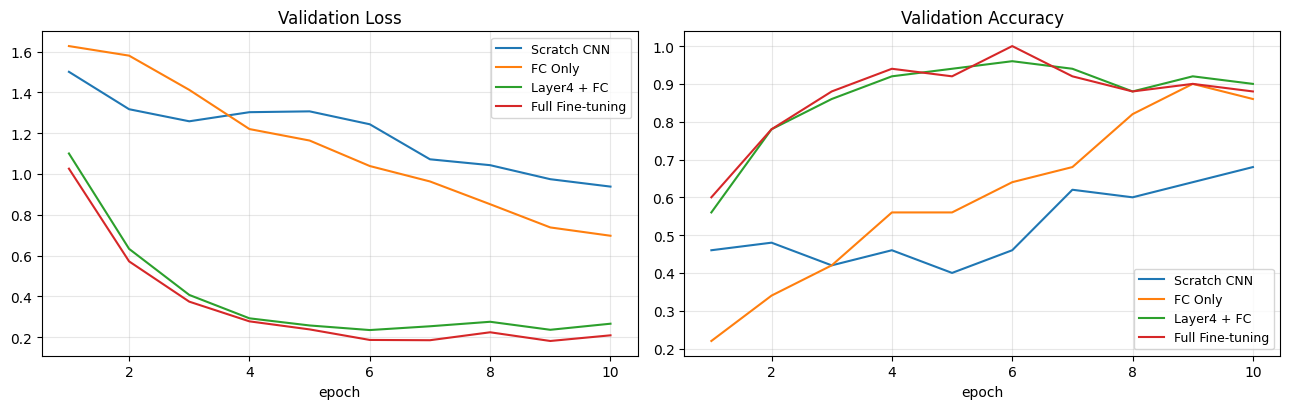

In [6]:
# 답안

# 모델별 결과 비교표 생성
rows = []

for name, r in results.items():
    rows.append({
        "모델": name,
        "학습 파라미터": f"{r['train_params']:,}",
        "최종 검증 정확도": round(r["hist"][-1][1], 4),
        "최고 검증 정확도": round(max(h[1] for h in r["hist"]), 4),
        "학습 시간(초)": round(r["time"], 1),
    })

table = pd.DataFrame(rows)
print(table.to_string(index=False))

# 최고 검증 정확도를 기준으로 가장 좋은 모델 선택
best = table.loc[table["최고 검증 정확도"].idxmax(), "모델"]
print(f"\n가장 좋은 모델: {best}")

# 그래프 범례 설정
labels = {
    "직접 만든 CNN": "Scratch CNN",
    "전이 · fc만": "FC Only",
    "전이 · layer4+fc": "Layer4 + FC",
    "전이 · 전체": "Full Fine-tuning"
}

# 모델별 학습 곡선 비교
xs = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

for name, r in results.items():
    ax[0].plot(xs, [h[0] for h in r["hist"]], label=labels[name])
    ax[1].plot(xs, [h[1] for h in r["hist"]], label=labels[name])

ax[0].set_title("Validation Loss")
ax[1].set_title("Validation Accuracy")

for a in ax:
    a.set_xlabel("epoch")
    a.legend(fontsize=9)
    a.grid(alpha=.3)

plt.tight_layout()
plt.show()


## 문제 5. 예측 결과 확인과 해석 (10점)
가장 좋은 모델로 검증 이미지 12장의 예측을 그리세요. 각 이미지에 **예측 클래스 · 예측 확률 · 실제 레이블**을 표시하고, 틀린 이미지도 따로 모아 보세요.

그리고 아래 세 가지를 각각 두세 줄로 적으세요.

1. 적은 데이터에서 전이학습이 유리한 이유
2. 층을 많이 풀수록 좋아지는가 — 이 데이터에서는 어땠나
3. 학습 시간과 정확도를 함께 볼 때 어느 모델을 고를 것인가


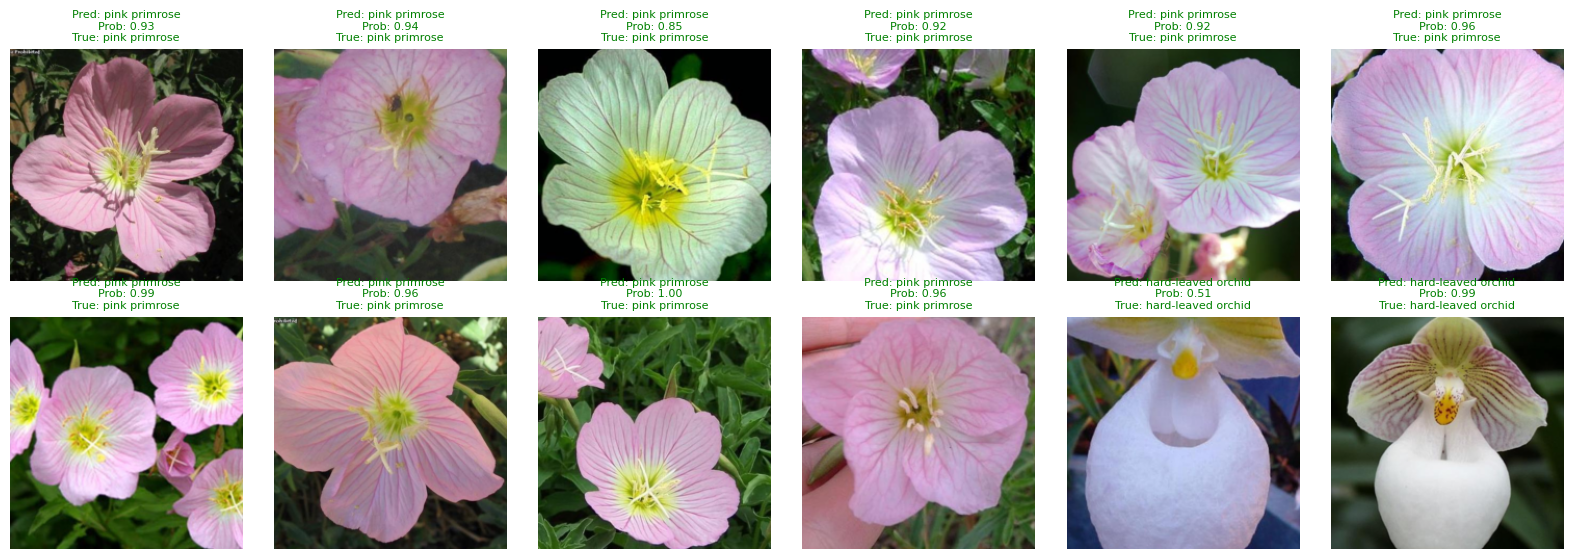

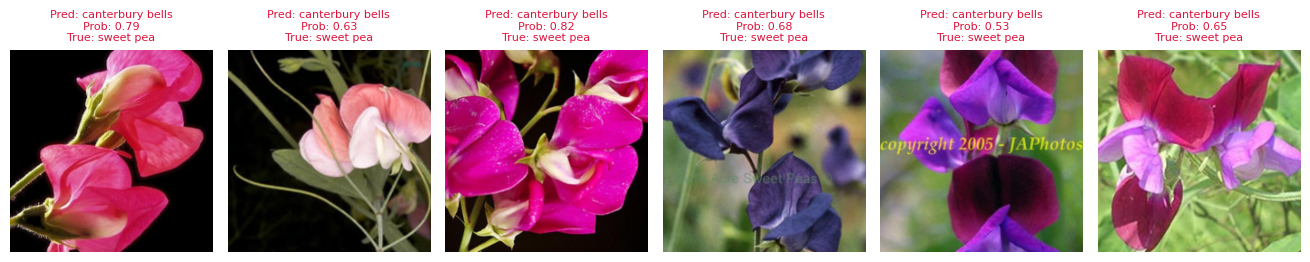

틀린 개수: 6


In [7]:
# 예측 결과 확인 코드

# 이미지 정규화 복원
inv = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

# 가장 좋은 모델 선택
model = results[best]["model"]
model.eval()

# 검증 이미지 예측 및 확률 계산
x, y = next(iter(val_loader))

with torch.no_grad():
    out = model(x.to(device))
    prob = torch.softmax(out, dim=1).cpu()
    pred = out.argmax(dim=1).cpu()

# 검증 이미지 12장 출력
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))

for ax, i in zip(axes.flatten(), range(12)):
    ax.imshow(inv(x[i]).permute(1, 2, 0).clamp(0, 1))
    ok = pred[i] == y[i]
    ax.set_title(
        f"Pred: {NAMES[pred[i]]}\n"
        f"Prob: {prob[i, pred[i]]:.2f}\n"
        f"True: {NAMES[y[i]]}",
        fontsize=8, color="green" if ok else "crimson"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

# 잘못 예측한 이미지 수집
imgs, trues, preds, probs = [], [], [], []

with torch.no_grad():
    for x, y in val_loader:
        out = model(x.to(device))
        p = out.argmax(dim=1).cpu()
        pr = torch.softmax(out, dim=1).cpu()
        wrong = p != y

        if wrong.any():
            imgs.append(x[wrong])
            trues.append(y[wrong])
            preds.append(p[wrong])
            probs.append(pr[wrong].max(dim=1).values)

# 잘못 예측한 이미지 출력
if imgs:
    imgs = torch.cat(imgs)
    trues = torch.cat(trues)
    preds = torch.cat(preds)
    probs = torch.cat(probs)

    n = min(8, len(imgs))
    fig, axes = plt.subplots(1, n, figsize=(2.2*n, 3))

    for ax, i in zip([axes] if n == 1 else axes, range(n)):
        ax.imshow(inv(imgs[i]).permute(1, 2, 0).clamp(0, 1))
        ax.set_title(
            f"Pred: {NAMES[preds[i]]}\n"
            f"Prob: {probs[i]:.2f}\n"
            f"True: {NAMES[trues[i]]}",
            fontsize=8, color="crimson"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    print("틀린 개수:", len(imgs))
else:
    print("전부 맞혔습니다")


**답:**

1. 전이학습은 대규모 데이터에서 이미 학습한 이미지 특징을 활용하므로 적은 데이터로도 효과적인 학습이 가능하다. 실제로 직접 만든 CNN보다 모든 전이학습 모델에서 높은 검증 정확도를 보였다.

2. 최종 검증 정확도는 마지막 계층만 학습했을 때 86%, layer4와 마지막 계층을 학습했을 때 90%, 전체 미세조정에서 88%로 나타났다. 따라서 학습하는 층을 늘린다고 정확도가 항상 향상되는 것은 아니다.

3. layer4와 마지막 계층을 학습한 모델을 선택하겠다. 학습 시간은 7.3초로 비교적 짧으며, 최종 검증 정확도가 90%로 가장 높아 학습 시간과 정확도를 함께 고려했을 때 적절하다고 판단하였다.
